Статистична обробка агрегованих даних

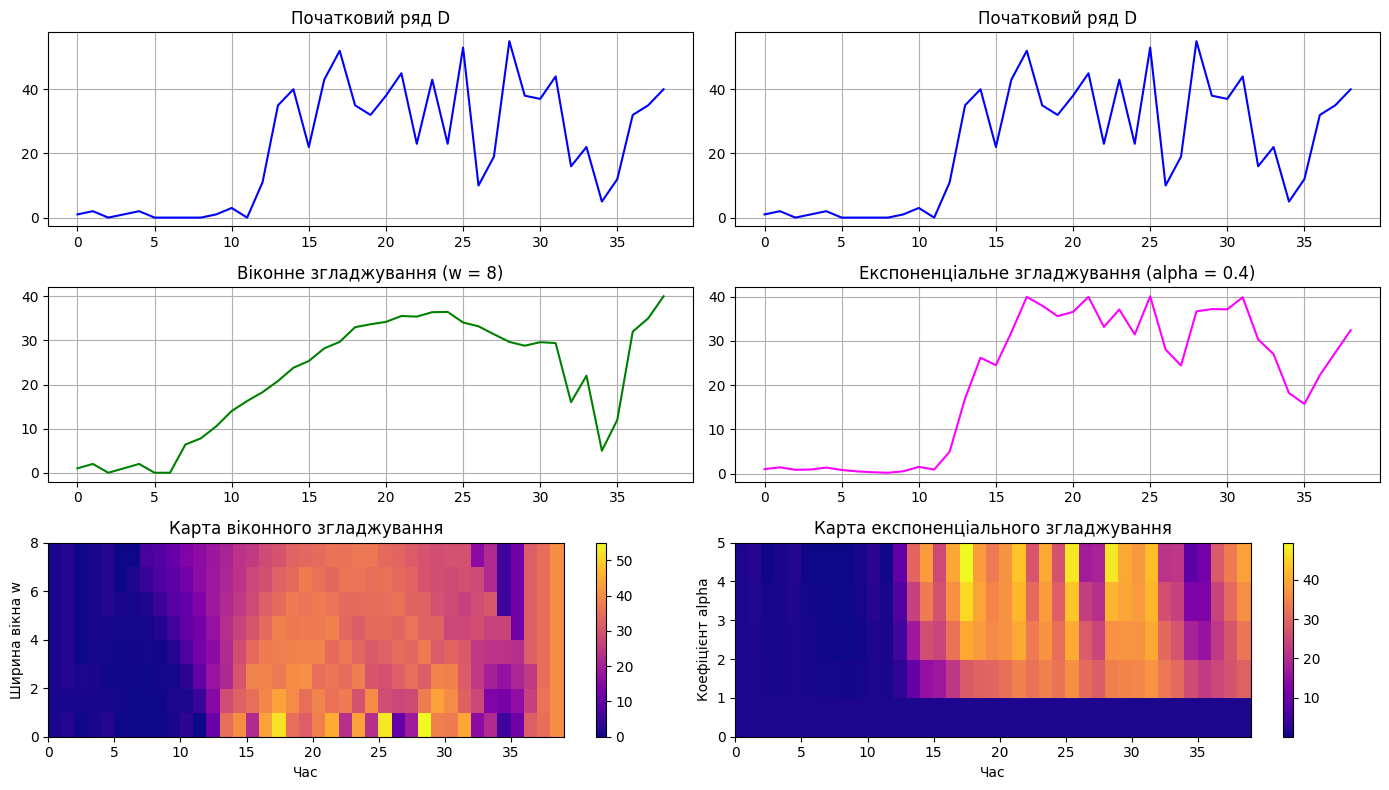

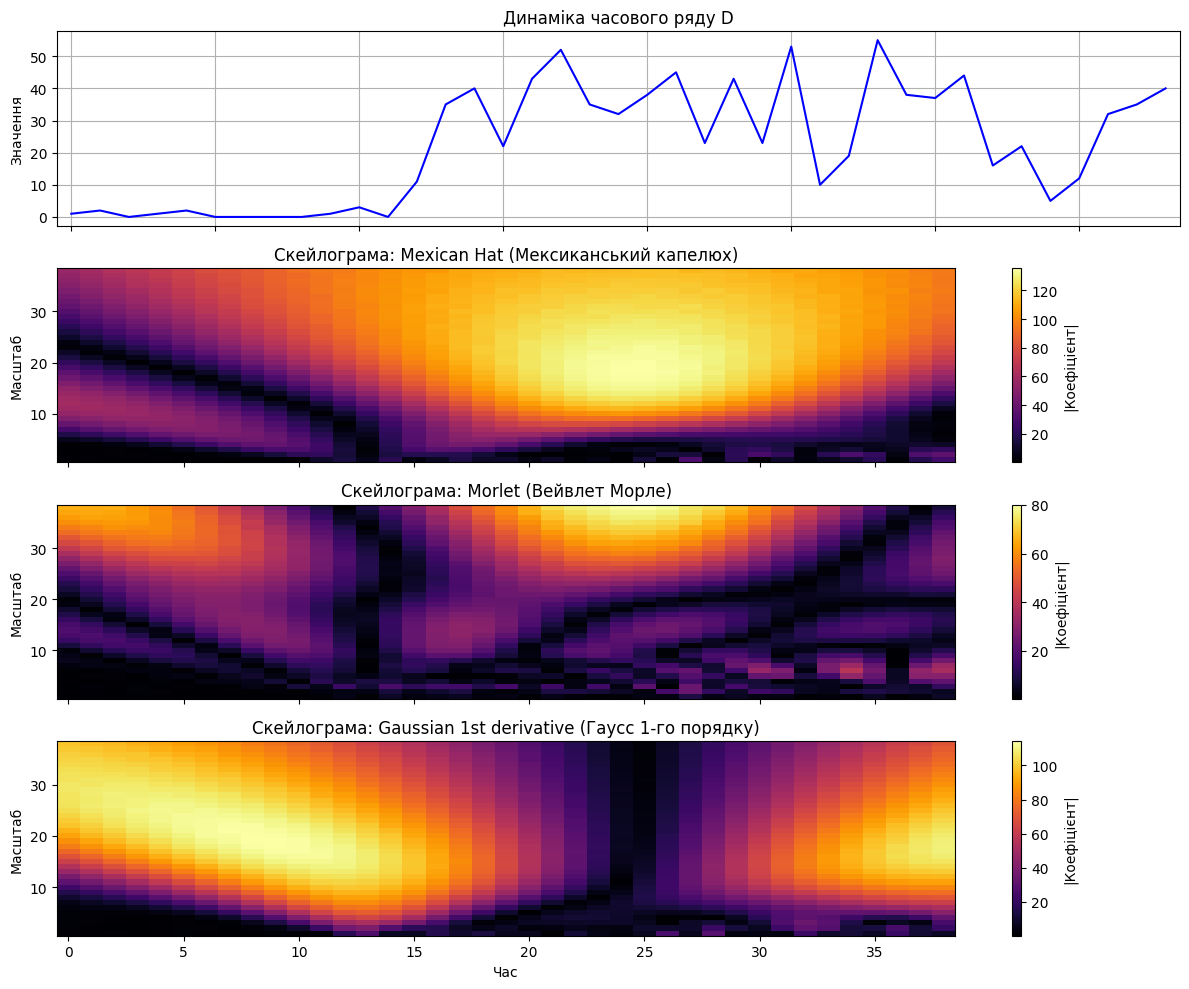

In [ ]:
!pip install PyWavelets matplotlib numpy -q

import numpy as np
import matplotlib.pyplot as plt
import pywt
D = [1, 2, 0, 1, 2, 0, 0, 0, 0, 1, 3, 0, 11, 35, 40, 22, 43, 52, 35, 32,
     38, 45, 23, 43, 23, 53, 10, 19, 55, 38, 37, 44, 16, 22, 5, 12, 32, 35, 40]

N = len(D)
t = np.arange(N)
M_win = 8
Z_win = np.zeros((M_win, N))
for i in range(N):
    for j in range(M_win):
        Z_win[j][i] = D[i]

for j in range(M_win):
    for k in range(j, N - j):
        Z_win[j][k] = 0
        for l in range(1, j + 1):
            Z_win[j][k] += D[k - l] + D[k + l]
        Z_win[j][k] += D[k]
        Z_win[j][k] /= (2 * j + 1)

M_exp = 5
Z_exp = np.zeros((M_exp, N))
for i in range(N):
    for j in range(M_exp):
        Z_exp[j][i] = D[i]

for j in range(M_exp):
    alf = j / M_exp
    for k in range(1, N):
        Z_exp[j][k] = D[k] * alf + Z_exp[j][k - 1] * (1 - alf)

fig, axes = plt.subplots(3, 2, figsize=(14, 8))

axes[0, 0].plot(t, D, color='blue')
axes[0, 0].set_title("Початковий ряд D")
axes[0, 0].grid(True)

axes[1, 0].plot(t, Z_win[7], color='green')
axes[1, 0].set_title("Віконне згладжування (w = 8)")
axes[1, 0].grid(True)

im0 = axes[2, 0].pcolor(Z_win, cmap='plasma')
axes[2, 0].set_title("Карта віконного згладжування")
axes[2, 0].set_xlabel("Час")
axes[2, 0].set_ylabel("Ширина вікна w")
fig.colorbar(im0, ax=axes[2, 0])

axes[0, 1].plot(t, D, color='blue')
axes[0, 1].set_title("Початковий ряд D")
axes[0, 1].grid(True)

axes[1, 1].plot(t, Z_exp[2], color='magenta')
axes[1, 1].set_title("Експоненціальне згладжування (alpha = 0.4)")
axes[1, 1].grid(True)

im1 = axes[2, 1].pcolor(Z_exp, cmap='plasma')
axes[2, 1].set_title("Карта експоненціального згладжування")
axes[2, 1].set_xlabel("Час")
axes[2, 1].set_ylabel("Коефіцієнт alpha")
fig.colorbar(im1, ax=axes[2, 1])

plt.tight_layout()
plt.show()
scales = np.arange(1, N)
wavelets = {
    'mexh': 'Mexican Hat (Мексиканський капелюх)',
    'morl': 'Morlet (Вейвлет Морле)',
    'gaus1': 'Gaussian 1st derivative (Гаусс 1-го порядку)'
}

fig, axes = plt.subplots(len(wavelets) + 1, 1, figsize=(12, 10), sharex=True)

axes[0].plot(t, D, 'b-', linewidth=1.5)
axes[0].grid(True)
axes[0].set_ylabel("Значення")
axes[0].set_title("Динаміка часового ряду D")

for idx, (wavelet, name) in enumerate(wavelets.items(), start=1):
    cwtmatr, freqs = pywt.cwt(D, scales, wavelet)
    pcm = axes[idx].pcolormesh(t, scales, np.abs(cwtmatr), cmap='inferno', shading='auto')
    axes[idx].set_ylabel("Масштаб")
    axes[idx].set_title(f"Скейлограма: {name}")
    fig.colorbar(pcm, ax=axes[idx], orientation='vertical', label='|Коефіцієнт|')

axes[-1].set_xlabel("Час")
plt.tight_layout()
plt.show()